In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path(r"E:\week 1\Mega_Supermart_HR_Dataset_2025.xlsx")

df = pd.read_excel(DATA_PATH, sheet_name="Employee Data")
dd = pd.read_excel(DATA_PATH, sheet_name="Data Dictionary")

print("Employee Data:", df.shape)
print("Data Dictionary:", dd.shape)

df.head()

Employee Data: (1200, 17)
Data Dictionary: (17, 3)


,EmployeeID,StoreID,City,Province,BusinessUnit,Division,Department,JobTitle,Gender,BirthDate,HireDate,AgeYears,LengthOfServiceYears,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate
0,ACE00001,ST03,Red Deer,AB,Prairie,West,Operations,Store Operations Supervisor,Woman,1982-02-17,2025-12-07,43,0.07,Full-time,2080,56.0,0.0269
1,ACE00002,ST04,Vancouver,BC,Pacific,West,Sales,Sales Supervisor,Man,1980-03-16,2023-09-21,45,2.28,Full-time,2080,0.0,0.0000
2,ACE00003,ST04,Vancouver,BC,Pacific,West,Inventory,Stock Associate,Man,1991-04-14,2021-12-11,34,4.05,Full-time,2080,44.0,0.0212
3,ACE00004,ST07,Kelowna,BC,Pacific,West,Sales,Senior Sales Associate,Man,2006-11-16,2024-12-31,19,1.00,Full-time,2080,0.0,0.0000
4,ACE00005,ST04,Vancouver,BC,Pacific,West,Sales,Senior Sales Associate,Woman,1987-04-06,2025-06-08,38,0.56,Full-time,2080,56.0,0.0269


In [4]:
import pandas as pd

# Load Excel file
file_path = r"C:\Users\surface\Mega_Supermart_HR_Dataset_2025.xlsx"

# Read both sheets
excel_file = pd.ExcelFile(file_path)

print("Available sheets:", excel_file.sheet_names)

Available sheets: ['Employee Data', 'Data Dictionary']


In [5]:
employee_data = pd.read_excel(
    file_path,
    sheet_name="Employee Data"
)

data_dictionary = pd.read_excel(
    file_path,
    sheet_name="Data Dictionary"
)

print("Employee Data Shape:", employee_data.shape)
print("Data Dictionary Shape:", data_dictionary.shape)

Employee Data Shape: (1200, 17)
Data Dictionary Shape: (17, 3)


In [6]:
# 1. Dataset dimensions
print("Employee Data:", employee_data.shape)
print("Data Dictionary:", data_dictionary.shape)

# 2. Column names
print("\nColumn Names:")
print(employee_data.columns.tolist())

# 3. Data types and non-null counts
print("\nDataset Information:")
employee_data.info()

# 4. First 5 records
print("\nFirst 5 Employee Records:")
display(employee_data.head())

# 5. Data Dictionary
print("\nData Dictionary:")
display(data_dictionary)

Employee Data: (1200, 17)
Data Dictionary: (17, 3)

Column Names:
['EmployeeID', 'StoreID', 'City', 'Province', 'BusinessUnit', 'Division', 'Department', 'JobTitle', 'Gender', 'BirthDate', 'HireDate', 'AgeYears', 'LengthOfServiceYears', 'EmploymentType', 'ScheduledHours2025', 'AbsentHours', 'AbsenceRate']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   EmployeeID            1200 non-null   object        
 1   StoreID               1200 non-null   object        
 2   City                  1200 non-null   object        
 3   Province              1200 non-null   object        
 4   BusinessUnit          1200 non-null   object        
 5   Division              1200 non-null   object        
 6   Department            1200 non-null   object        
 7   JobTitle              1200 non-null  

,EmployeeID,StoreID,City,Province,BusinessUnit,Division,Department,JobTitle,Gender,BirthDate,HireDate,AgeYears,LengthOfServiceYears,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate
0,ACE00001,ST03,Red Deer,AB,Prairie,West,Operations,Store Operations Supervisor,Woman,1982-02-17,2025-12-07,43,0.07,Full-time,2080,56.0,0.0269
1,ACE00002,ST04,Vancouver,BC,Pacific,West,Sales,Sales Supervisor,Man,1980-03-16,2023-09-21,45,2.28,Full-time,2080,0.0,0.0000
2,ACE00003,ST04,Vancouver,BC,Pacific,West,Inventory,Stock Associate,Man,1991-04-14,2021-12-11,34,4.05,Full-time,2080,44.0,0.0212
3,ACE00004,ST07,Kelowna,BC,Pacific,West,Sales,Senior Sales Associate,Man,2006-11-16,2024-12-31,19,1.00,Full-time,2080,0.0,0.0000
4,ACE00005,ST04,Vancouver,BC,Pacific,West,Sales,Senior Sales Associate,Woman,1987-04-06,2025-06-08,38,0.56,Full-time,2080,56.0,0.0269



Data Dictionary:


,Field,Type / unit,Definition
0,EmployeeID,Text,Anonymized employee key;
1,StoreID,Text,Store key ST01 to ST11.
2,City,Text,Western Canadian store city.
3,Province,Text,"AB, BC, MB or SK."
4,BusinessUnit,Text,Prairie or Pacific retail group.
5,Division,Text,West or Central operating division.
6,Department,Text,Employee department;
7,JobTitle,Text,Role within department.
8,Gender,Text,Self-reported category;
9,BirthDate,Date,Date of birth.


In [7]:
# Missing values analysis

missing_values = employee_data.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': (
        missing_values / len(employee_data) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values(by='Missing Count', ascending=False)

display(missing_summary)

,Missing Count,Missing Percentage
Gender,3,0.25
AbsentHours,2,0.17
AbsenceRate,2,0.17


In [8]:
# Identify records with missing values

missing_records = employee_data[
    employee_data.isnull().any(axis=1)
]

display(missing_records)

,EmployeeID,StoreID,City,Province,BusinessUnit,Division,Department,JobTitle,Gender,BirthDate,HireDate,AgeYears,LengthOfServiceYears,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate
84,ACE00085,ST01,Calgary,AB,Prairie,West,Management,Assistant Store Manager,NaN,1974-10-26,2022-02-09,51,3.89,Full-time,2080,36.0,0.0173
200,ACE00201,ST02,Edmonton,AB,Prairie,West,Sales,Senior Sales Associate,Man,2007-02-21,2025-12-31,18,0.00,Part-time,1040,NaN,NaN
379,ACE00380,ST07,Kelowna,BC,Pacific,West,Sales,Sales Associate,NaN,2002-10-16,2023-09-09,23,2.31,Full-time,2080,32.0,0.0154
703,ACE00704,ST01,Calgary,AB,Prairie,West,Sales,Sales Associate,Woman,1979-07-02,2025-09-29,46,0.25,Full-time,2080,NaN,NaN
908,ACE00909,ST06,Victoria,BC,Pacific,West,Sales,Senior Sales Associate,NaN,2007-12-27,2025-12-31,18,0.00,Part-time,1248,0.0,0.0000


In [9]:
print("Gender Categories:")
print(employee_data['Gender'].value_counts(dropna=False))

Gender Categories:
Gender
Man                  589
Woman                562
Prefer not to say     24
Non-binary            22
NaN                    3
Name: count, dtype: int64


In [10]:
# Step B: Attendance statistics

print("Absent Hours Statistics:")
display(employee_data['AbsentHours'].describe())

print("\nAbsence Rate Statistics:")
display(employee_data['AbsenceRate'].describe())

Absent Hours Statistics:


count    1198.000000
mean       46.731219
std        59.411254
min         0.000000
25%        12.000000
50%        32.000000
75%        64.000000
max       720.000000
Name: AbsentHours, dtype: float64


Absence Rate Statistics:


count    1198.000000
mean        0.027053
std         0.038985
min         0.000000
25%         0.005800
50%         0.017300
75%         0.035125
max         0.576900
Name: AbsenceRate, dtype: float64

In [11]:
import numpy as np

# Calculate absence rate independently
calculated_rate = (
    employee_data['AbsentHours'] /
    employee_data['ScheduledHours2025']
)

# Compare calculated rate with original rate
valid_records = employee_data['AbsenceRate'].notna()

match = np.isclose(
    calculated_rate[valid_records],
    employee_data.loc[valid_records, 'AbsenceRate'],
    atol=0.0001
)

print("Records checked:", valid_records.sum())
print("Matching records:", match.sum())
print("Mismatching records:", (~match).sum())

Records checked: 1198
Matching records: 1198
Mismatching records: 0


In [12]:
top_absence = employee_data.nlargest(
    10, 'AbsentHours'
)

display(
    top_absence[
        ['EmployeeID',
         'City',
         'Department',
         'JobTitle',
         'EmploymentType',
         'ScheduledHours2025',
         'AbsentHours',
         'AbsenceRate']
    ]
)

,EmployeeID,City,Department,JobTitle,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate
1000,ACE01001,Winnipeg,Customer Service,Customer Service Associate,Full-time,2080,720.0,0.3462
326,ACE00327,Victoria,Human Resources,HR Business Partner,Part-time,1248,600.0,0.4808
393,ACE00394,Edmonton,Sales,Sales Supervisor,Part-time,1040,600.0,0.5769
42,ACE00043,Edmonton,Sales,Sales Associate,Full-time,2080,496.0,0.2385
1045,ACE01046,Surrey,Sales,Senior Sales Associate,Full-time,2080,496.0,0.2385
69,ACE00070,Winnipeg,Inventory,Inventory Supervisor,Full-time,2080,420.0,0.2019
636,ACE00637,Calgary,Sales,Sales Associate,Full-time,2080,420.0,0.2019
825,ACE00826,Regina,Sales,Senior Sales Associate,Part-time,1040,400.0,0.3846
439,ACE00440,Surrey,Sales,Sales Associate,Full-time,2080,344.0,0.1654
1134,ACE01135,Regina,Customer Service,Customer Service Supervisor,Full-time,2080,308.0,0.1481


In [13]:
top_absence_rate = employee_data.nlargest(
    10, 'AbsenceRate'
)

display(
    top_absence_rate[
        ['EmployeeID',
         'City',
         'Department',
         'JobTitle',
         'EmploymentType',
         'ScheduledHours2025',
         'AbsentHours',
         'AbsenceRate']
    ]
)

,EmployeeID,City,Department,JobTitle,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate
393,ACE00394,Edmonton,Sales,Sales Supervisor,Part-time,1040,600.0,0.5769
326,ACE00327,Victoria,Human Resources,HR Business Partner,Part-time,1248,600.0,0.4808
825,ACE00826,Regina,Sales,Senior Sales Associate,Part-time,1040,400.0,0.3846
1000,ACE01001,Winnipeg,Customer Service,Customer Service Associate,Full-time,2080,720.0,0.3462
42,ACE00043,Edmonton,Sales,Sales Associate,Full-time,2080,496.0,0.2385
1045,ACE01046,Surrey,Sales,Senior Sales Associate,Full-time,2080,496.0,0.2385
1150,ACE01151,Red Deer,Sales,Sales Supervisor,Part-time,1040,248.0,0.2385
1183,ACE01184,Regina,Sales,Senior Sales Associate,Part-time,1040,240.0,0.2308
69,ACE00070,Winnipeg,Inventory,Inventory Supervisor,Full-time,2080,420.0,0.2019
636,ACE00637,Calgary,Sales,Sales Associate,Full-time,2080,420.0,0.2019


In [14]:
Q1 = employee_data['AbsentHours'].quantile(0.25)
Q3 = employee_data['AbsentHours'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = employee_data[
    (employee_data['AbsentHours'] < lower_bound) |
    (employee_data['AbsentHours'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Q1: 12.0
Q3: 64.0
IQR: 52.0
Lower Bound: -66.0
Upper Bound: 142.0
Number of Outliers: 50


In [15]:
# Compare absence by employment type

employment_analysis = (
    employee_data
    .groupby('EmploymentType')
    .agg(
        Employee_Count=('EmployeeID', 'count'),
        Total_Scheduled_Hours=('ScheduledHours2025', 'sum'),
        Total_Absent_Hours=('AbsentHours', 'sum'),
        Average_Absent_Hours=('AbsentHours', 'mean'),
        Average_Absence_Rate=('AbsenceRate', 'mean')
    )
)

# Calculate weighted absence rate
employment_analysis['Weighted_Absence_Rate'] = (
    employment_analysis['Total_Absent_Hours'] /
    employment_analysis['Total_Scheduled_Hours']
)

display(employment_analysis.round(4))

,Employee_Count,Total_Scheduled_Hours,Total_Absent_Hours,Average_Absent_Hours,Average_Absence_Rate,Weighted_Absence_Rate
EmploymentType,,,,,,
Full-time,863,1795040,39908.0,46.2970,0.0223,0.0222
Part-time,337,429104,16076.0,47.8452,0.0394,0.0375


In [16]:
# Compare absence across departments

department_analysis = (
    employee_data
    .groupby('Department')
    .agg(
        Employee_Count=('EmployeeID', 'count'),
        Average_Absent_Hours=('AbsentHours', 'mean'),
        Total_Absent_Hours=('AbsentHours', 'sum'),
        Average_Absence_Rate=('AbsenceRate', 'mean')
    )
    .sort_values(
        by='Average_Absence_Rate',
        ascending=False
    )
)

display(department_analysis.round(4))

,Employee_Count,Average_Absent_Hours,Total_Absent_Hours,Average_Absence_Rate
Department,,,,
sales,1,60.0000,60.0,0.0481
Customer Service,190,62.9895,11968.0,0.0357
Sales,444,57.4480,25392.0,0.0336
Human Resources,68,46.7059,3176.0,0.0273
Customer service,1,32.0000,32.0,0.0205
Inventory,228,34.1404,7784.0,0.0194
Management,129,30.4806,3932.0,0.0179
Operations,139,26.1871,3640.0,0.0153


In [17]:
# Normalize department names

employee_data['Department_Clean'] = (
    employee_data['Department']
    .str.strip()
    .str.title()
)

# Check normalized categories

print(
    employee_data['Department_Clean']
    .value_counts(dropna=False)
)

Department_Clean
Sales               445
Inventory           228
Customer Service    191
Operations          139
Management          129
Human Resources      68
Name: count, dtype: int64


In [18]:
department_analysis_clean = (
    employee_data
    .groupby('Department_Clean')
    .agg(
        Employee_Count=('EmployeeID', 'nunique'),
        Attendance_Records=('AbsentHours', 'count'),
        Total_Scheduled_Hours=('ScheduledHours2025', 'sum'),
        Total_Absent_Hours=('AbsentHours', 'sum'),
        Average_Absent_Hours=('AbsentHours', 'mean'),
        Average_Absence_Rate=('AbsenceRate', 'mean')
    )
)

department_analysis_clean['Weighted_Absence_Rate'] = (
    department_analysis_clean['Total_Absent_Hours'] /
    department_analysis_clean['Total_Scheduled_Hours']
)

department_analysis_clean = (
    department_analysis_clean
    .sort_values('Weighted_Absence_Rate', ascending=False)
)

display(department_analysis_clean.round(4))

,Employee_Count,Attendance_Records,Total_Scheduled_Hours,Total_Absent_Hours,Average_Absent_Hours,Average_Absence_Rate,Weighted_Absence_Rate
Department_Clean,,,,,,,
Customer Service,191,191,355056,12000.0,62.8272,0.0356,0.0338
Sales,445,443,828568,25452.0,57.4537,0.0336,0.0307
Human Resources,68,68,127504,3176.0,46.7059,0.0273,0.0249
Inventory,228,228,418496,7784.0,34.1404,0.0194,0.0186
Management,129,129,240656,3932.0,30.4806,0.0179,0.0163
Operations,139,139,253864,3640.0,26.1871,0.0153,0.0143


In [19]:
# Calculate weighted absence rate using valid attendance records only

valid_attendance = employee_data.dropna(
    subset=['AbsentHours', 'AbsenceRate']
)

department_valid = (
    valid_attendance
    .groupby('Department_Clean')
    .agg(
        Valid_Employees=('EmployeeID', 'nunique'),
        Valid_Scheduled_Hours=('ScheduledHours2025', 'sum'),
        Total_Absent_Hours=('AbsentHours', 'sum')
    )
)

department_valid['Valid_Weighted_Absence_Rate'] = (
    department_valid['Total_Absent_Hours'] /
    department_valid['Valid_Scheduled_Hours']
)

display(department_valid.round(4))

,Valid_Employees,Valid_Scheduled_Hours,Total_Absent_Hours,Valid_Weighted_Absence_Rate
Department_Clean,,,,
Customer Service,191,355056,12000.0,0.0338
Human Resources,68,127504,3176.0,0.0249
Inventory,228,418496,7784.0,0.0186
Management,129,240656,3932.0,0.0163
Operations,139,253864,3640.0,0.0143
Sales,443,825448,25452.0,0.0308


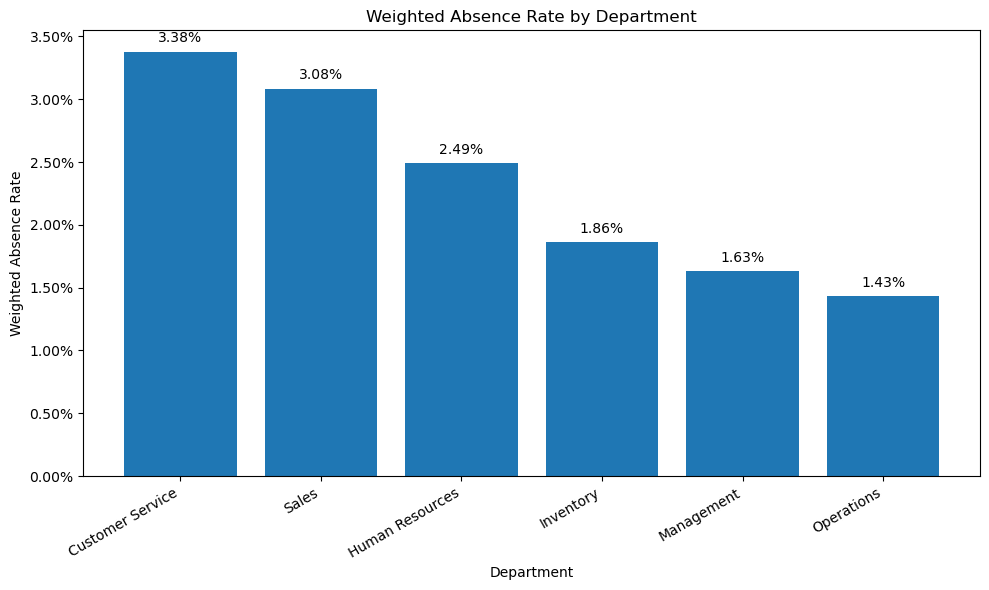

In [20]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Prepare data for plotting
plot_data = department_valid[
    'Valid_Weighted_Absence_Rate'
].sort_values(ascending=False)

# Create chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    plot_data.index,
    plot_data.values
)

# Format y-axis as percentage
plt.gca().yaxis.set_major_formatter(
    mtick.PercentFormatter(1.0)
)

# Add value labels
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.0005,
        f'{value:.2%}',
        ha='center',
        va='bottom'
    )

plt.title('Weighted Absence Rate by Department')
plt.xlabel('Department')
plt.ylabel('Weighted Absence Rate')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

plt.show()

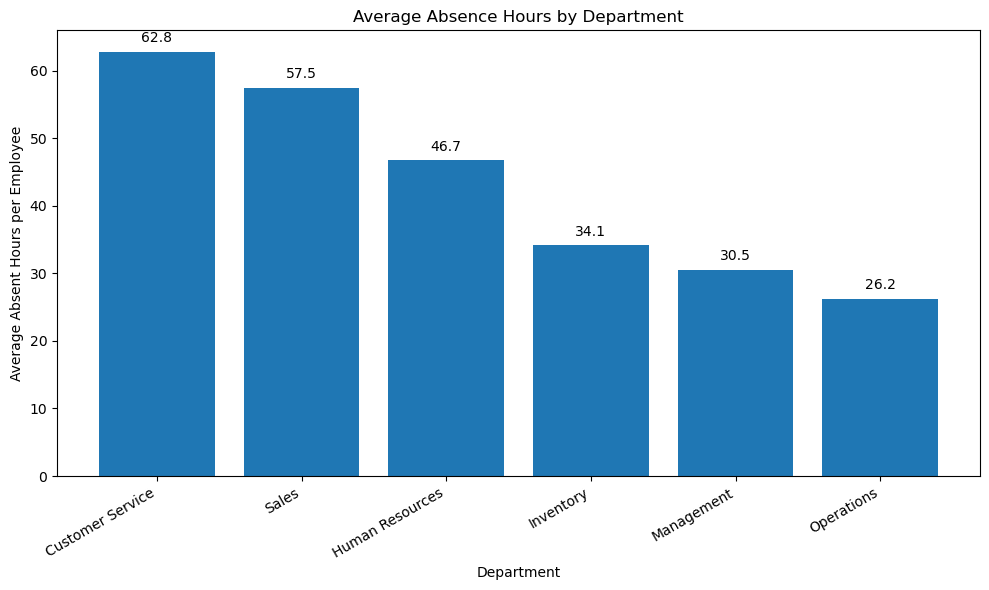

In [21]:
# Average absence hours by department

avg_absence = (
    valid_attendance.groupby('Department_Clean')['AbsentHours']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_absence.index,
    avg_absence.values
)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f'{value:.1f}',
        ha='center',
        va='bottom'
    )

plt.title('Average Absence Hours by Department')
plt.xlabel('Department')
plt.ylabel('Average Absent Hours per Employee')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

plt.show()

In [22]:
# Calculate median absence hours by department

median_absence = (
    valid_attendance.groupby('Department_Clean')['AbsentHours']
    .median()
    .sort_values(ascending=False)
)

print("Median Absence Hours by Department:")
display(median_absence.round(1))

Median Absence Hours by Department:


Department_Clean
Customer Service    44.0
Sales               40.0
Human Resources     32.0
Inventory           28.0
Management          24.0
Operations          20.0
Name: AbsentHours, dtype: float64

C:\Users\surface\AppData\Local\Temp\ipykernel_49364\3191701461.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


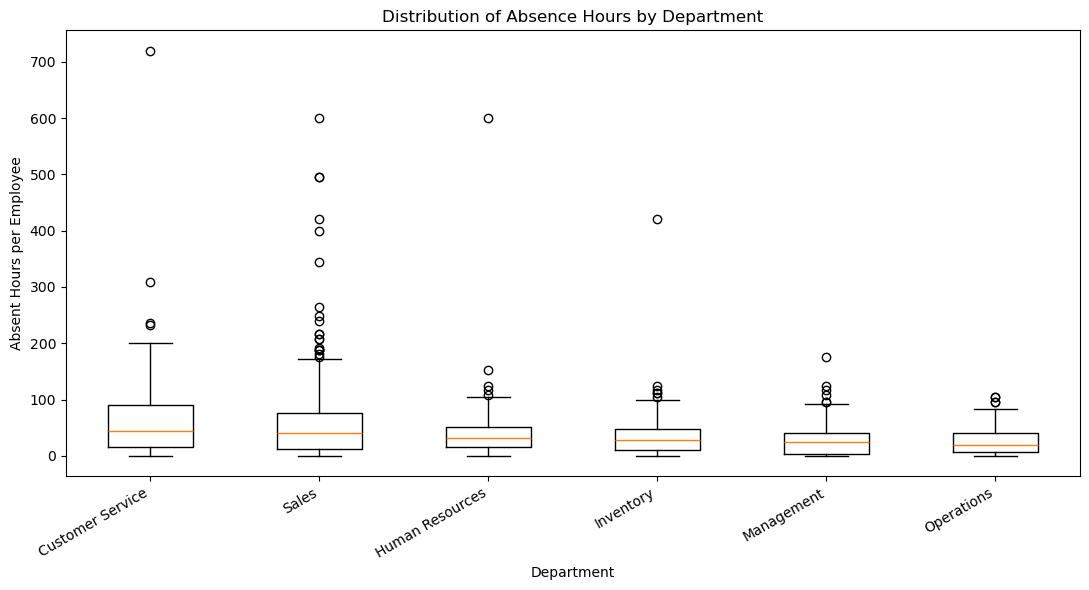

In [23]:
# Box plot: Absence Hours by Department

departments = [
    'Customer Service',
    'Sales',
    'Human Resources',
    'Inventory',
    'Management',
    'Operations'
]

boxplot_data = [
    valid_attendance.loc[
        valid_attendance['Department_Clean'] == dept,
        'AbsentHours'
    ].dropna()
    for dept in departments
]

plt.figure(figsize=(11, 6))

plt.boxplot(
    boxplot_data,
    labels=departments,
    showfliers=True
)

plt.title('Distribution of Absence Hours by Department')
plt.xlabel('Department')
plt.ylabel('Absent Hours per Employee')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

plt.show()

In [24]:
# Calculate outliers by department using the IQR method

outlier_results = []

for dept, group in valid_attendance.groupby('Department_Clean'):

    values = group['AbsentHours'].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) |
        (values > upper_bound)
    ]

    outlier_results.append({
        'Department': dept,
        'Employee_Count': len(values),
        'Outlier_Count': len(outliers),
        'Outlier_Rate': len(outliers) / len(values),
        'Upper_Bound': upper_bound
    })

outlier_analysis = pd.DataFrame(outlier_results)

outlier_analysis = outlier_analysis.sort_values(
    'Outlier_Rate',
    ascending=False
)

display(outlier_analysis.round(3))

,Department,Employee_Count,Outlier_Count,Outlier_Rate,Upper_Bound
1,Human Resources,68,5,0.074,106.0
3,Management,129,6,0.047,94.0
5,Sales,443,19,0.043,172.0
4,Operations,139,4,0.029,91.0
2,Inventory,228,6,0.026,103.5
0,Customer Service,191,4,0.021,201.0


In [4]:
import pandas as pd

# Load HR dataset
file_path = r"C:\Users\surface\Mega_Supermart_HR_Dataset_2025.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1200, 17)


,EmployeeID,StoreID,City,Province,BusinessUnit,Division,Department,JobTitle,Gender,BirthDate,HireDate,AgeYears,LengthOfServiceYears,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate
0,ACE00001,ST03,Red Deer,AB,Prairie,West,Operations,Store Operations Supervisor,Woman,1982-02-17,2025-12-07,43,0.07,Full-time,2080,56.0,0.0269
1,ACE00002,ST04,Vancouver,BC,Pacific,West,Sales,Sales Supervisor,Man,1980-03-16,2023-09-21,45,2.28,Full-time,2080,0.0,0.0000
2,ACE00003,ST04,Vancouver,BC,Pacific,West,Inventory,Stock Associate,Man,1991-04-14,2021-12-11,34,4.05,Full-time,2080,44.0,0.0212
3,ACE00004,ST07,Kelowna,BC,Pacific,West,Sales,Senior Sales Associate,Man,2006-11-16,2024-12-31,19,1.00,Full-time,2080,0.0,0.0000
4,ACE00005,ST04,Vancouver,BC,Pacific,West,Sales,Senior Sales Associate,Woman,1987-04-06,2025-06-08,38,0.56,Full-time,2080,56.0,0.0269


In [5]:
# Check all column names

print("Total Columns:", len(df.columns))

for col in df.columns:
    print(col)

Total Columns: 17
EmployeeID
StoreID
City
Province
BusinessUnit
Division
Department
JobTitle
Gender
BirthDate
HireDate
AgeYears
LengthOfServiceYears
EmploymentType
ScheduledHours2025
AbsentHours
AbsenceRate


In [6]:
# Top 10 employees with highest absence hours

top_10_absence = (
    df.sort_values(
        by='AbsentHours',
        ascending=False
    )
    [['EmployeeID', 'Department',
      'JobTitle', 'ScheduledHours2025',
      'AbsentHours', 'AbsenceRate']]
    .head(10)
    .copy()
)

display(top_10_absence)

,EmployeeID,Department,JobTitle,ScheduledHours2025,AbsentHours,AbsenceRate
1000,ACE01001,Customer Service,Customer Service Associate,2080,720.0,0.3462
393,ACE00394,Sales,Sales Supervisor,1040,600.0,0.5769
326,ACE00327,Human Resources,HR Business Partner,1248,600.0,0.4808
1045,ACE01046,Sales,Senior Sales Associate,2080,496.0,0.2385
42,ACE00043,Sales,Sales Associate,2080,496.0,0.2385
69,ACE00070,Inventory,Inventory Supervisor,2080,420.0,0.2019
636,ACE00637,Sales,Sales Associate,2080,420.0,0.2019
825,ACE00826,Sales,Senior Sales Associate,1040,400.0,0.3846
439,ACE00440,Sales,Sales Associate,2080,344.0,0.1654
1134,ACE01135,Customer Service,Customer Service Supervisor,2080,308.0,0.1481


,EmployeeID,Department,JobTitle,ScheduledHours2025,AbsentHours,AbsenceRate,Outlier
1000,ACE01001,Customer Service,Customer Service Associate,2080,720.0,0.3462,True
393,ACE00394,Sales,Sales Supervisor,1040,600.0,0.5769,True
326,ACE00327,Human Resources,HR Business Partner,1248,600.0,0.4808,True
1045,ACE01046,Sales,Senior Sales Associate,2080,496.0,0.2385,True
42,ACE00043,Sales,Sales Associate,2080,496.0,0.2385,True
69,ACE00070,Inventory,Inventory Supervisor,2080,420.0,0.2019,True
636,ACE00637,Sales,Sales Associate,2080,420.0,0.2019,True
825,ACE00826,Sales,Senior Sales Associate,1040,400.0,0.3846,True
439,ACE00440,Sales,Sales Associate,2080,344.0,0.1654,True
1134,ACE01135,Customer Service,Customer Service Supervisor,2080,308.0,0.1481,True


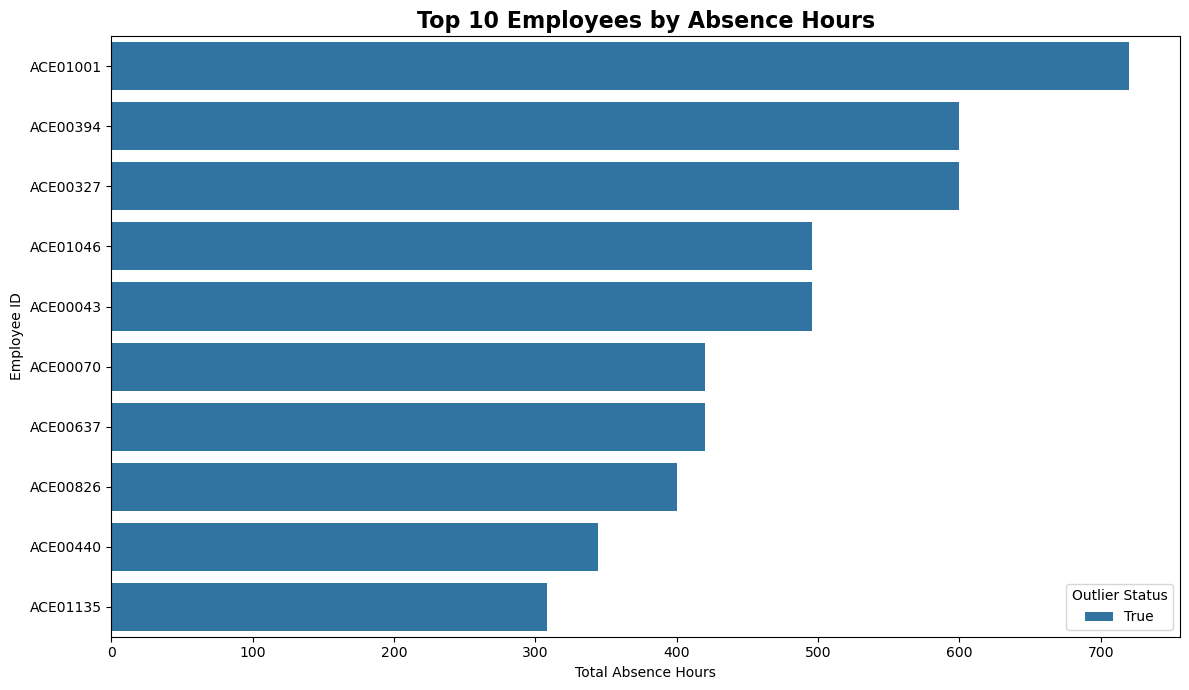

IQR Upper Limit: 142.0


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate IQR outlier threshold
Q1 = df['AbsentHours'].quantile(0.25)
Q3 = df['AbsentHours'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

# Prepare Top 10 dataset
top_10_absence = (
    df.sort_values('AbsentHours', ascending=False)
    [['EmployeeID', 'Department', 'JobTitle',
      'ScheduledHours2025', 'AbsentHours', 'AbsenceRate']]
    .head(10)
    .copy()
)

top_10_absence['Outlier'] = (
    top_10_absence['AbsentHours'] > upper_limit
)

# Display results
display(top_10_absence)

# Create chart
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_10_absence,
    x='AbsentHours',
    y='EmployeeID',
    hue='Outlier',
    dodge=False
)

plt.title('Top 10 Employees by Absence Hours',
          fontsize=16, fontweight='bold')

plt.xlabel('Total Absence Hours')
plt.ylabel('Employee ID')

plt.legend(title='Outlier Status')
plt.tight_layout()
plt.show()

print("IQR Upper Limit:", upper_limit)

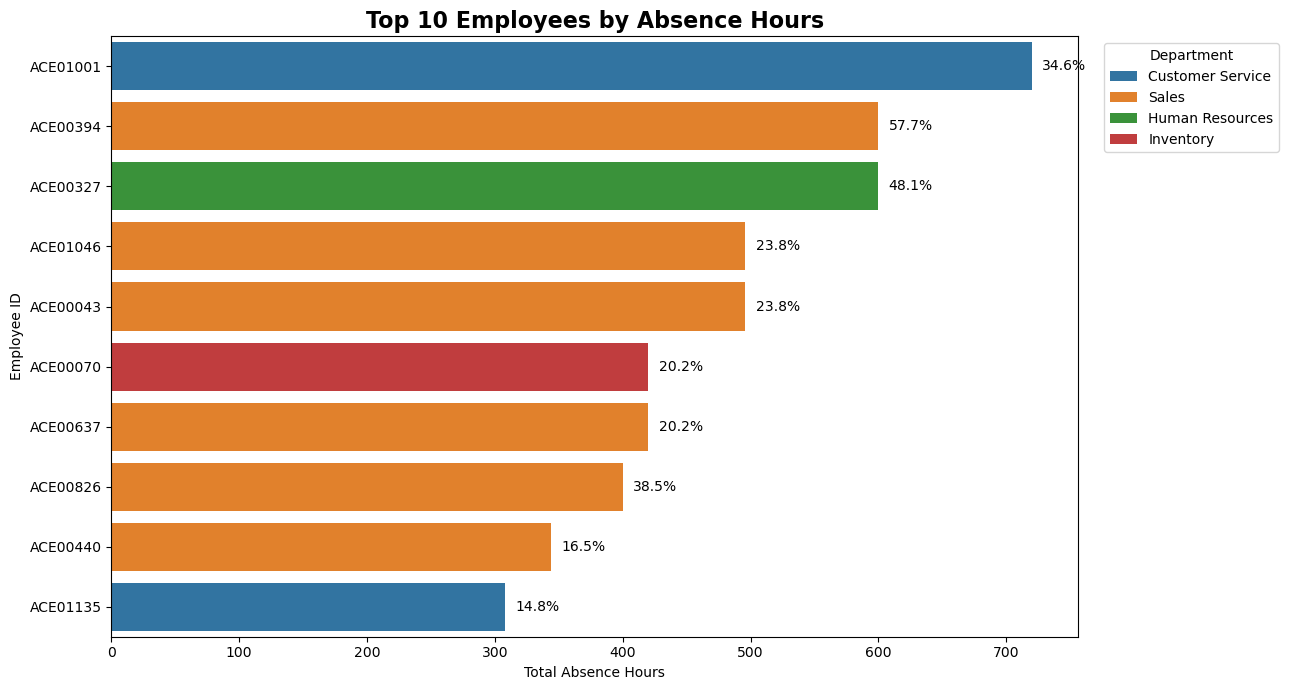

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(13, 7))

ax = sns.barplot(
    data=top_10_absence,
    x='AbsentHours',
    y='EmployeeID',
    hue='Department',
    dodge=False
)

# Add absence rate labels
for i, row in enumerate(
    top_10_absence.itertuples()
):
    ax.text(
        row.AbsentHours + 8,
        i,
        f'{row.AbsenceRate:.1%}',
        va='center',
        fontsize=10
    )

plt.title(
    'Top 10 Employees by Absence Hours',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Total Absence Hours')
plt.ylabel('Employee ID')

plt.legend(
    title='Department',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

In [9]:
# Select numerical variables for correlation analysis

correlation_data = df[
    [
        'AgeYears',
        'LengthOfServiceYears',
        'ScheduledHours2025',
        'AbsentHours',
        'AbsenceRate'
    ]
].copy()

display(correlation_data.head())

,AgeYears,LengthOfServiceYears,ScheduledHours2025,AbsentHours,AbsenceRate
0,43,0.07,2080,56.0,0.0269
1,45,2.28,2080,0.0,0.0000
2,34,4.05,2080,44.0,0.0212
3,19,1.00,2080,0.0,0.0000
4,38,0.56,2080,56.0,0.0269


In [10]:
# Check missing values

print("Missing Values:")
print(correlation_data.isnull().sum())

# Check data types
print("\nData Types:")
print(correlation_data.dtypes)

# Summary statistics
display(correlation_data.describe())

Missing Values:
AgeYears                0
LengthOfServiceYears    0
ScheduledHours2025      0
AbsentHours             2
AbsenceRate             2
dtype: int64

Data Types:
AgeYears                  int64
LengthOfServiceYears    float64
ScheduledHours2025        int64
AbsentHours             float64
AbsenceRate             float64
dtype: object


,AgeYears,LengthOfServiceYears,ScheduledHours2025,AbsentHours,AbsenceRate
count,1200.000000,1200.000000,1200.000000,1198.000000,1198.000000
mean,38.594167,4.540817,1853.453333,46.731219,0.027053
std,11.287558,4.500646,379.411732,59.411254,0.038985
min,18.000000,0.000000,1040.000000,0.000000,0.000000
25%,30.000000,1.170000,1560.000000,12.000000,0.005800
50%,38.000000,3.065000,2080.000000,32.000000,0.017300
75%,47.000000,6.522500,2080.000000,64.000000,0.035125
max,66.000000,27.000000,2080.000000,720.000000,0.576900


In [11]:
# Identify records with missing absence data

missing_records = df[
    df['AbsentHours'].isnull() |
    df['AbsenceRate'].isnull()
]

display(missing_records)

,EmployeeID,StoreID,City,Province,BusinessUnit,Division,Department,JobTitle,Gender,BirthDate,HireDate,AgeYears,LengthOfServiceYears,EmploymentType,ScheduledHours2025,AbsentHours,AbsenceRate
200,ACE00201,ST02,Edmonton,AB,Prairie,West,Sales,Senior Sales Associate,Man,2007-02-21,2025-12-31,18,0.00,Part-time,1040,NaN,NaN
703,ACE00704,ST01,Calgary,AB,Prairie,West,Sales,Sales Associate,Woman,1979-07-02,2025-09-29,46,0.25,Full-time,2080,NaN,NaN


In [12]:
# Validate absence rate calculation

df['CalculatedAbsenceRate'] = (
    df['AbsentHours'] /
    df['ScheduledHours2025']
)

rate_difference = (
    df['AbsenceRate'] -
    df['CalculatedAbsenceRate']
).abs()

print(
    "Records with inconsistent absence rates:",
    (rate_difference > 0.0002).sum()
)

Records with inconsistent absence rates: 0


In [13]:
# Prepare complete data for correlation analysis

correlation_data_clean = correlation_data.dropna().copy()

print("Original records:", len(correlation_data))
print("Complete records:", len(correlation_data_clean))
print("Excluded records:", 
      len(correlation_data) - len(correlation_data_clean))

# Calculate Pearson correlation

correlation_matrix = correlation_data_clean.corr(
    method='pearson'
)

display(correlation_matrix.round(3))

Original records: 1200
Complete records: 1198
Excluded records: 2


,AgeYears,LengthOfServiceYears,ScheduledHours2025,AbsentHours,AbsenceRate
AgeYears,1.000,0.196,-0.026,-0.075,-0.065
LengthOfServiceYears,0.196,1.000,-0.078,-0.121,-0.096
ScheduledHours2025,-0.026,-0.078,1.000,-0.027,-0.232
AbsentHours,-0.075,-0.121,-0.027,1.000,0.934
AbsenceRate,-0.065,-0.096,-0.232,0.934,1.000


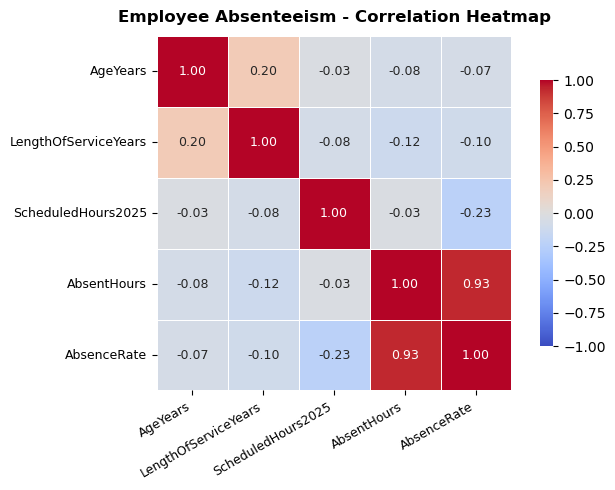

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    annot_kws={'size': 9},
    cbar_kws={'shrink': 0.75}
)

plt.title(
    'Employee Absenteeism - Correlation Heatmap',
    fontsize=12,
    fontweight='bold',
    pad=10
)

plt.xticks(rotation=30, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

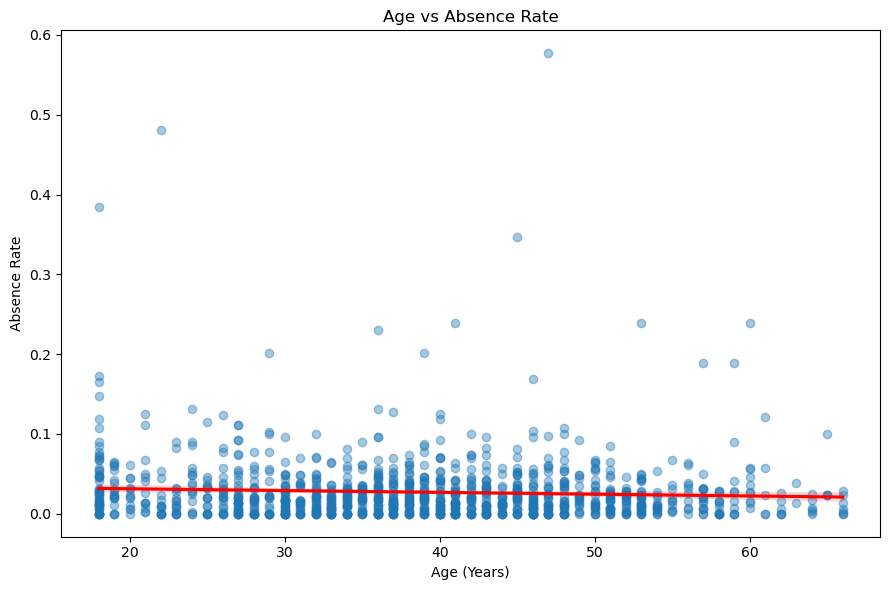

In [16]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=correlation_data_clean,
    x='AgeYears',
    y='AbsenceRate',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Age vs Absence Rate')
plt.xlabel('Age (Years)')
plt.ylabel('Absence Rate')

plt.tight_layout()
plt.show()

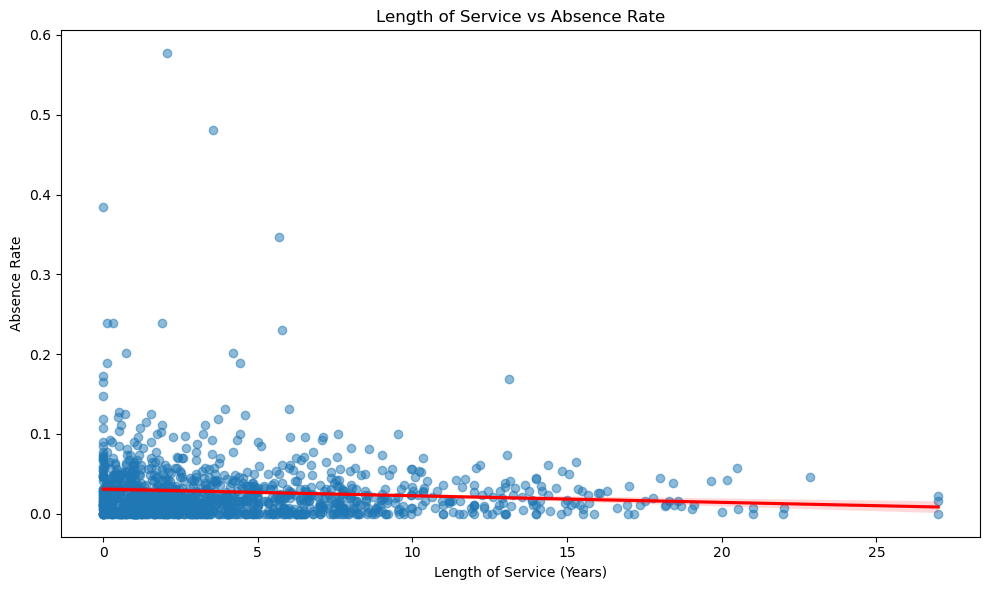

In [17]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=correlation_data_clean,
    x='LengthOfServiceYears',
    y='AbsenceRate',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)

plt.title('Length of Service vs Absence Rate')
plt.xlabel('Length of Service (Years)')
plt.ylabel('Absence Rate')

plt.tight_layout()
plt.show()

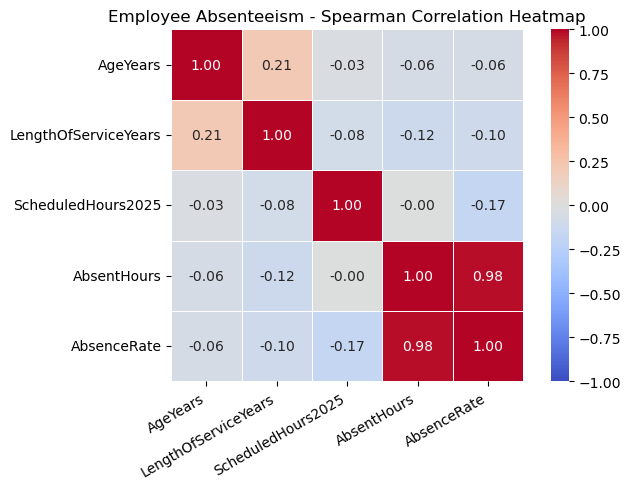

In [18]:
spearman_matrix = correlation_data_clean.corr(method='spearman')

plt.figure(figsize=(7, 5))

sns.heatmap(
    spearman_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title('Employee Absenteeism - Spearman Correlation Heatmap')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [19]:
employment_summary = (
    df.groupby('EmploymentType')
    .agg(
        Employee_Count=('EmployeeID', 'count'),
        Average_Absent_Hours=('AbsentHours', 'mean'),
        Median_Absent_Hours=('AbsentHours', 'median'),
        Average_Absence_Rate=('AbsenceRate', 'mean'),
        Median_Absence_Rate=('AbsenceRate', 'median')
    )
    .round(3)
)

employment_summary

,Employee_Count,Average_Absent_Hours,Median_Absent_Hours,Average_Absence_Rate,Median_Absence_Rate
EmploymentType,,,,,
Full-time,863,46.297,32.0,0.022,0.015
Part-time,337,47.845,32.0,0.039,0.023


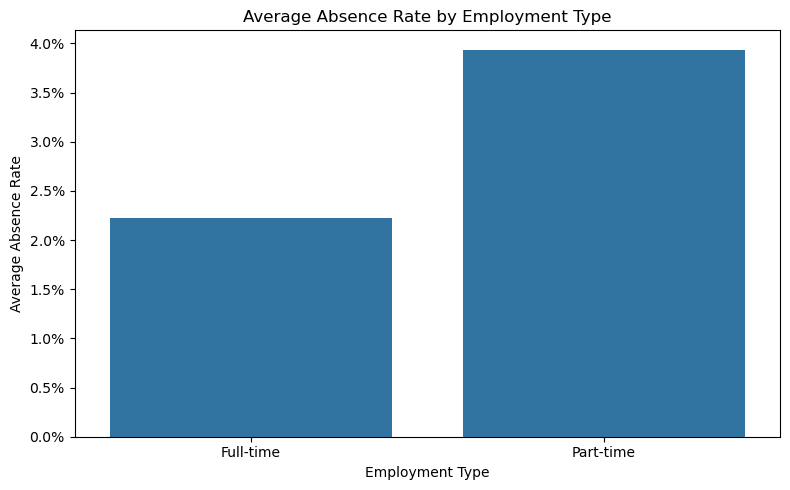

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='EmploymentType',
    y='AbsenceRate',
    errorbar=None
)

plt.title('Average Absence Rate by Employment Type')
plt.xlabel('Employment Type')
plt.ylabel('Average Absence Rate')

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y:.1%}')
)

plt.tight_layout()
plt.show()

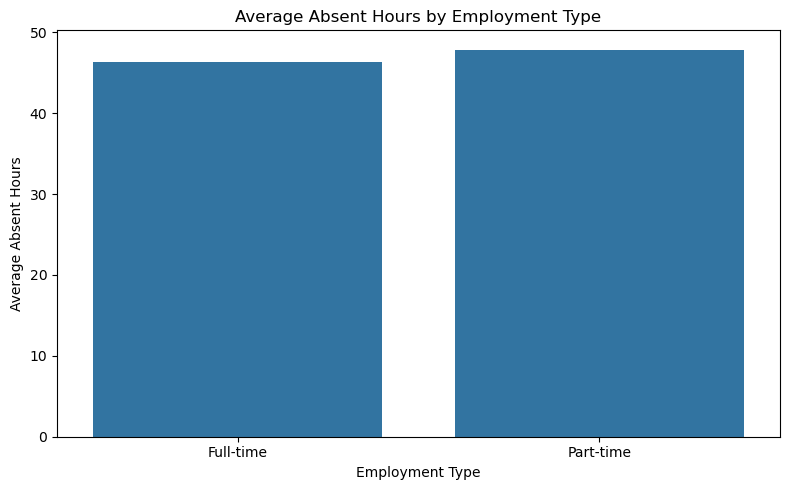

In [21]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='EmploymentType',
    y='AbsentHours',
    errorbar=None
)

plt.title('Average Absent Hours by Employment Type')
plt.xlabel('Employment Type')
plt.ylabel('Average Absent Hours')

plt.tight_layout()
plt.show()

In [22]:
from scipy.stats import ttest_ind

full_time = df.loc[
    df['EmploymentType'] == 'Full-time',
    'AbsenceRate'
].dropna()

part_time = df.loc[
    df['EmploymentType'] == 'Part-time',
    'AbsenceRate'
].dropna()

t_stat, p_value = ttest_ind(
    full_time,
    part_time,
    equal_var=False
)

print("Full-time sample size:", len(full_time))
print("Part-time sample size:", len(part_time))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 6))

Full-time sample size: 862
Part-time sample size: 336
T-statistic: -5.2437
P-value: 0.0


In [23]:
print("Full-time:")
print("Mean:", round(full_time.mean(), 4))
print("Standard Deviation:", round(full_time.std(), 4))

print("\nPart-time:")
print("Mean:", round(part_time.mean(), 4))
print("Standard Deviation:", round(part_time.std(), 4))

Full-time:
Mean: 0.0223
Standard Deviation: 0.0275

Part-time:
Mean: 0.0394
Standard Deviation: 0.0573


In [24]:
import numpy as np

n1 = len(full_time)
n2 = len(part_time)

mean1 = full_time.mean()
mean2 = part_time.mean()

sd1 = full_time.std()
sd2 = part_time.std()

# Pooled standard deviation
pooled_sd = np.sqrt(
    ((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2)
    / (n1 + n2 - 2)
)

# Cohen's d
cohens_d = (mean2 - mean1) / pooled_sd

print("Pooled Standard Deviation:", round(pooled_sd, 4))
print("Cohen's d:", round(cohens_d, 4))

Pooled Standard Deviation: 0.0382
Cohen's d: 0.4472


In [25]:
from scipy import stats
import numpy as np

# Mean difference: Part-time minus Full-time
mean_diff = part_time.mean() - full_time.mean()

# Welch's standard error
se = np.sqrt(
    full_time.var(ddof=1) / len(full_time)
    + part_time.var(ddof=1) / len(part_time)
)

# Welch-Satterthwaite degrees of freedom
s1 = full_time.var(ddof=1) / len(full_time)
s2 = part_time.var(ddof=1) / len(part_time)

df_welch = (s1 + s2)**2 / (
    s1**2 / (len(full_time) - 1)
    + s2**2 / (len(part_time) - 1)
)

# 95% confidence interval
t_critical = stats.t.ppf(0.975, df_welch)

ci_lower = mean_diff - t_critical * se
ci_upper = mean_diff + t_critical * se

# Hedges' g
correction = 1 - (3 / (4 * (n1 + n2) - 9))
hedges_g = correction * cohens_d

print("Mean Difference:", round(mean_diff, 4))
print("95% CI:", round(ci_lower, 4), "to", round(ci_upper, 4))
print("Welch Degrees of Freedom:", round(df_welch, 2))
print("Hedges' g:", round(hedges_g, 4))

Mean Difference: 0.0171
95% CI: 0.0107 to 0.0235
Welch Degrees of Freedom: 396.66
Hedges' g: 0.4469


In [26]:
department_employment_summary = (
    df.groupby(['Department', 'EmploymentType'])
    .agg(
        Valid_Employees=('AbsenceRate', 'count'),
        Average_Absence_Rate=('AbsenceRate', 'mean'),
        Median_Absence_Rate=('AbsenceRate', 'median'),
        Average_Absent_Hours=('AbsentHours', 'mean')
    )
    .round(4)
    .reset_index()
)

department_employment_summary

,Department,EmploymentType,Valid_Employees,Average_Absence_Rate,Median_Absence_Rate,Average_Absent_Hours
0,Customer Service,Full-time,135,0.0308,0.0231,64.0593
1,Customer Service,Part-time,55,0.0477,0.0308,60.3636
2,Customer service,Part-time,1,0.0205,0.0205,32.0000
3,Human Resources,Full-time,50,0.0202,0.0154,42.0000
4,Human Resources,Part-time,18,0.0469,0.0212,59.7778
5,Inventory,Full-time,154,0.0175,0.0154,36.3636
6,Inventory,Part-time,74,0.0234,0.0185,29.5135
7,Management,Full-time,97,0.0139,0.0115,28.8660
8,Management,Part-time,32,0.0301,0.0173,35.3750
9,Operations,Full-time,97,0.0121,0.0096,25.1546


In [27]:
# Create a cleaned department column
df['Department_Clean'] = (
    df['Department']
    .str.strip()
    .str.title()
)

# Check department names before and after cleaning
print("Original Department Names:")
print(sorted(df['Department'].dropna().unique()))

print("\nCleaned Department Names:")
print(sorted(df['Department_Clean'].dropna().unique()))

Original Department Names:
['Customer Service', 'Customer service', 'Human Resources', 'Inventory', 'Management', 'Operations', 'Sales', 'sales']

Cleaned Department Names:
['Customer Service', 'Human Resources', 'Inventory', 'Management', 'Operations', 'Sales']


In [28]:
department_employment_summary = (
    df.groupby(['Department_Clean', 'EmploymentType'])
    .agg(
        Valid_Employees=('AbsenceRate', 'count'),
        Average_Absence_Rate=('AbsenceRate', 'mean'),
        Median_Absence_Rate=('AbsenceRate', 'median'),
        Average_Absent_Hours=('AbsentHours', 'mean')
    )
    .round(4)
    .reset_index()
)

department_employment_summary

,Department_Clean,EmploymentType,Valid_Employees,Average_Absence_Rate,Median_Absence_Rate,Average_Absent_Hours
0,Customer Service,Full-time,135,0.0308,0.0231,64.0593
1,Customer Service,Part-time,56,0.0472,0.0298,59.8571
2,Human Resources,Full-time,50,0.0202,0.0154,42.0000
3,Human Resources,Part-time,18,0.0469,0.0212,59.7778
4,Inventory,Full-time,154,0.0175,0.0154,36.3636
5,Inventory,Part-time,74,0.0234,0.0185,29.5135
6,Management,Full-time,97,0.0139,0.0115,28.8660
7,Management,Part-time,32,0.0301,0.0173,35.3750
8,Operations,Full-time,97,0.0121,0.0096,25.1546
9,Operations,Part-time,42,0.0228,0.0244,28.5714


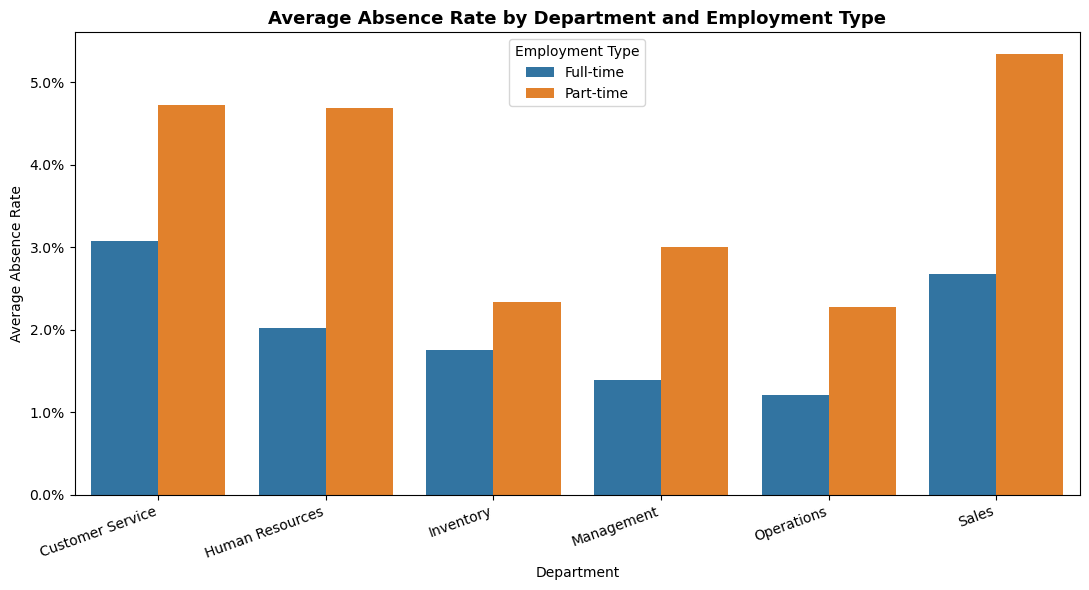

In [29]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=department_employment_summary,
    x='Department_Clean',
    y='Average_Absence_Rate',
    hue='EmploymentType',
    errorbar=None
)

plt.title(
    'Average Absence Rate by Department and Employment Type',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Department')
plt.ylabel('Average Absence Rate')
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y:.1%}')
)

plt.xticks(rotation=20, ha='right')
plt.legend(title='Employment Type')
plt.tight_layout()
plt.show()

In [30]:

# Overall Absence Rate Analysis

# 1. Select records with valid absence data
valid_absence = df.dropna(
    subset=['AbsentHours', 'AbsenceRate']
).copy()

# 2. Calculate total hours
total_absent_hours = valid_absence['AbsentHours'].sum()

total_scheduled_hours = valid_absence[
    'ScheduledHours2025'
].sum()

# 3. Calculate overall absence indicators
weighted_absence_rate = (
    total_absent_hours / total_scheduled_hours
)

mean_absence_rate = valid_absence[
    'AbsenceRate'
].mean()

median_absence_rate = valid_absence[
    'AbsenceRate'
].median()

average_absent_hours = valid_absence[
    'AbsentHours'
].mean()

median_absent_hours = valid_absence[
    'AbsentHours'
].median()

# 4. Display results
print("OVERALL ABSENCE ANALYSIS")
print("-" * 40)

print("Total Employees:", len(df))
print("Valid Absence Records:", len(valid_absence))
print("Missing Absence Records:", len(df) - len(valid_absence))

print("Total Absent Hours:", total_absent_hours)
print("Total Scheduled Hours:", total_scheduled_hours)

print(f"Weighted Absence Rate: {weighted_absence_rate:.2%}")
print(f"Mean Employee Absence Rate: {mean_absence_rate:.2%}")
print(f"Median Employee Absence Rate: {median_absence_rate:.2%}")

print(f"Average Absent Hours: {average_absent_hours:.2f}")
print(f"Median Absent Hours: {median_absent_hours:.2f}")


OVERALL ABSENCE ANALYSIS
----------------------------------------
Total Employees: 1200
Valid Absence Records: 1198
Missing Absence Records: 2
Total Absent Hours: 55984.0
Total Scheduled Hours: 2221024
Weighted Absence Rate: 2.52%
Mean Employee Absence Rate: 2.71%
Median Employee Absence Rate: 1.73%
Average Absent Hours: 46.73
Median Absent Hours: 32.00


In [31]:
# Employee Demographic Analysis: Age Groups

# 1. Select employees with valid absence records
age_df = df.dropna(
    subset=['AgeYears', 'AbsentHours', 'AbsenceRate']
).copy()

# 2. Define age categories
age_bins = [18, 30, 40, 50, 60, float('inf')]

age_labels = [
    '18-29',
    '30-39',
    '40-49',
    '50-59',
    '60+'
]

# 3. Create AgeGroup column
age_df['AgeGroup'] = pd.cut(
    age_df['AgeYears'],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# 4. Calculate absence statistics by age group
age_summary = age_df.groupby(
    'AgeGroup', observed=False
).agg(
    Employee_Count=('EmployeeID', 'count'),
    Average_Absence_Rate=('AbsenceRate', 'mean'),
    Median_Absence_Rate=('AbsenceRate', 'median'),
    Average_Absent_Hours=('AbsentHours', 'mean'),
    Median_Absent_Hours=('AbsentHours', 'median')
).reset_index()

# 5. Display results
print("ABSENCE ANALYSIS BY AGE GROUP")
print("-" * 60)

print(age_summary.round(3).to_string(index=False))


ABSENCE ANALYSIS BY AGE GROUP
------------------------------------------------------------
AgeGroup  Employee_Count  Average_Absence_Rate  Median_Absence_Rate  Average_Absent_Hours  Median_Absent_Hours
   18-29             265                 0.034                0.020                57.600                 40.0
   30-39             378                 0.024                0.017                42.328                 32.0
   40-49             336                 0.027                0.017                46.857                 32.0
   50-59             179                 0.023                0.015                39.017                 32.0
     60+              40                 0.028                0.016                49.800                 30.0


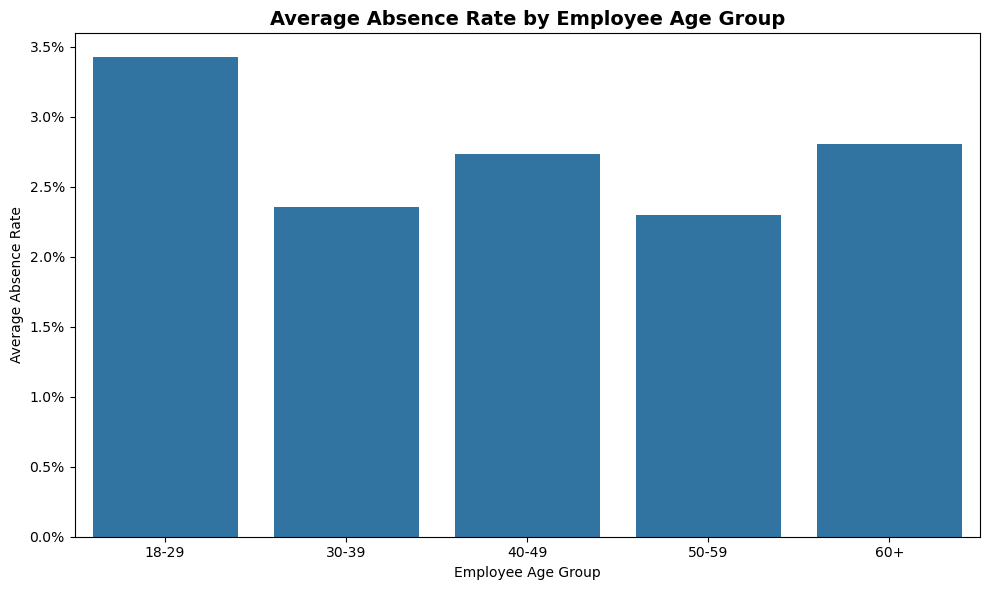

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_summary,
    x='AgeGroup',
    y='Average_Absence_Rate'
)

plt.title('Average Absence Rate by Employee Age Group',
          fontsize=14, fontweight='bold')

plt.xlabel('Employee Age Group')
plt.ylabel('Average Absence Rate')

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y:.1%}')
)

plt.tight_layout()
plt.show()


In [33]:

# Gender-Based Absence Analysis

# 1. Select valid records
gender_df = df.dropna(
    subset=['Gender', 'AbsentHours', 'AbsenceRate']
).copy()

# 2. Group employees by gender
gender_summary = gender_df.groupby(
    'Gender'
).agg(
    Employee_Count=('EmployeeID', 'count'),
    Average_Absence_Rate=('AbsenceRate', 'mean'),
    Median_Absence_Rate=('AbsenceRate', 'median'),
    Average_Absent_Hours=('AbsentHours', 'mean'),
    Median_Absent_Hours=('AbsentHours', 'median')
).reset_index()

# 3. Display results
print("ABSENCE ANALYSIS BY GENDER")
print("-" * 60)

print(gender_summary.round(3).to_string(index=False))


ABSENCE ANALYSIS BY GENDER
------------------------------------------------------------
           Gender  Employee_Count  Average_Absence_Rate  Median_Absence_Rate  Average_Absent_Hours  Median_Absent_Hours
              Man             588                 0.028                0.019                48.197                 32.0
       Non-binary              22                 0.018                0.015                32.182                 32.0
Prefer not to say              24                 0.023                0.019                41.000                 30.0
            Woman             561                 0.027                0.017                46.139                 32.0


In [34]:

# Length of Service Analysis

# 1. Select records with valid absence and service data
service_df = df.dropna(
    subset=[
        'LengthOfServiceYears',
        'AbsentHours',
        'AbsenceRate'
    ]
).copy()

# 2. Define service groups
service_bins = [
    -0.001, 2, 5, 10, float('inf')
]

service_labels = [
    'Less than 2 years',
    '2 to <5 years',
    '5 to <10 years',
    '10+ years'
]

# 3. Create ServiceGroup column
service_df['ServiceGroup'] = pd.cut(
    service_df['LengthOfServiceYears'],
    bins=service_bins,
    labels=service_labels,
    right=False
)

# 4. Calculate absence statistics
service_summary = service_df.groupby(
    'ServiceGroup', observed=False
).agg(
    Employee_Count=('EmployeeID', 'count'),
    Average_Absence_Rate=('AbsenceRate', 'mean'),
    Median_Absence_Rate=('AbsenceRate', 'median'),
    Average_Absent_Hours=('AbsentHours', 'mean'),
    Median_Absent_Hours=('AbsentHours', 'median')
).reset_index()

# 5. Display results
print("ABSENCE ANALYSIS BY LENGTH OF SERVICE")
print("-" * 65)

print(service_summary.round(3).to_string(index=False))


ABSENCE ANALYSIS BY LENGTH OF SERVICE
-----------------------------------------------------------------
     ServiceGroup  Employee_Count  Average_Absence_Rate  Median_Absence_Rate  Average_Absent_Hours  Median_Absent_Hours
Less than 2 years             431                 0.032                0.020                56.325                 40.0
    2 to <5 years             359                 0.026                0.017                44.022                 32.0
   5 to <10 years             270                 0.024                0.015                40.652                 28.0
        10+ years             138                 0.022                0.015                35.710                 30.0


In [35]:

from scipy.stats import pearsonr, spearmanr

# Select valid records
corr_df = df[
    ['AgeYears', 'LengthOfServiceYears', 'AbsenceRate']
].dropna()

# Test two key relationships
relationships = [
    ('AgeYears', 'AbsenceRate'),
    ('LengthOfServiceYears', 'AbsenceRate')
]

print("CORRELATION SIGNIFICANCE TEST")
print("-" * 65)

for x, y in relationships:

    pearson_r, pearson_p = pearsonr(
        corr_df[x], corr_df[y]
    )

    spearman_r, spearman_p = spearmanr(
        corr_df[x], corr_df[y]
    )

    print(f"\n{x} vs {y}")

    print(f"Pearson correlation: {pearson_r:.4f}")
    print(f"Pearson p-value: {pearson_p:.6f}")

    print(f"Spearman correlation: {spearman_r:.4f}")
    print(f"Spearman p-value: {spearman_p:.6f}")

    if pearson_p < 0.05:
        print("Pearson result: Statistically significant")
    else:
        print("Pearson result: Not statistically significant")


CORRELATION SIGNIFICANCE TEST
-----------------------------------------------------------------

AgeYears vs AbsenceRate
Pearson correlation: -0.0653
Pearson p-value: 0.023795
Spearman correlation: -0.0576
Spearman p-value: 0.046360
Pearson result: Statistically significant

LengthOfServiceYears vs AbsenceRate
Pearson correlation: -0.0960
Pearson p-value: 0.000880
Spearman correlation: -0.1046
Spearman p-value: 0.000287
Pearson result: Statistically significant


In [36]:

# Outlier Detection Using the IQR Method

# 1. Select employees with valid absence rates
outlier_df = df.dropna(
    subset=['AbsenceRate', 'EmployeeID']
).copy()

# 2. Calculate quartiles
Q1 = outlier_df['AbsenceRate'].quantile(0.25)
Q3 = outlier_df['AbsenceRate'].quantile(0.75)

# 3. Calculate IQR
IQR = Q3 - Q1

# 4. Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# 5. Identify potential outliers
high_absence = outlier_df[
    outlier_df['AbsenceRate'] > upper_bound
].copy()

# 6. Display statistical results
print("ABSENCE RATE OUTLIER DETECTION")
print("-" * 60)

print(f"Q1: {Q1:.4f} ({Q1:.2%})")
print(f"Q3: {Q3:.4f} ({Q3:.2%})")
print(f"IQR: {IQR:.4f}")
print(f"Lower Bound: {lower_bound:.4f}")
print(f"Upper Bound: {upper_bound:.4f}")

print("\nHIGH-ABSENCE OUTLIERS")
print("-" * 60)

print("Number of potential outliers:", len(high_absence))

print(
    f"Percentage of employees: "
    f"{len(high_absence) / len(outlier_df):.2%}"
)


ABSENCE RATE OUTLIER DETECTION
------------------------------------------------------------
Q1: 0.0058 (0.58%)
Q3: 0.0351 (3.51%)
IQR: 0.0293
Lower Bound: -0.0382
Upper Bound: 0.0791

HIGH-ABSENCE OUTLIERS
------------------------------------------------------------
Number of potential outliers: 63
Percentage of employees: 5.26%


In [37]:

# High-Absence Outliers by Department

# Standardise department names
outlier_df['Department'] = (
    outlier_df['Department'].astype(str).str.strip().str.title()
)

high_absence['Department'] = (
    high_absence['Department'].astype(str).str.strip().str.title()
)

# Total employees by department
department_total = outlier_df.groupby(
    'Department'
).agg(
    Total_Employees=('EmployeeID', 'count')
)

# High-absence employees by department
department_outliers = high_absence.groupby(
    'Department'
).agg(
    High_Absence_Count=('EmployeeID', 'count')
)

# Combine the two summaries
department_outlier_summary = department_total.join(
    department_outliers
).fillna(0)

department_outlier_summary['High_Absence_Count'] = (
    department_outlier_summary['High_Absence_Count'].astype(int)
)

department_outlier_summary['Outlier_Percentage'] = (
    department_outlier_summary['High_Absence_Count'] /
    department_outlier_summary['Total_Employees'] * 100
)

department_outlier_summary = (
    department_outlier_summary
    .sort_values('High_Absence_Count', ascending=False)
)

print("HIGH-ABSENCE EMPLOYEES BY DEPARTMENT")
print("-" * 65)

print(department_outlier_summary.round(2).to_string())


HIGH-ABSENCE EMPLOYEES BY DEPARTMENT
-----------------------------------------------------------------
                  Total_Employees  High_Absence_Count  Outlier_Percentage
Department                                                               
Sales                         443                  38                8.58
Customer Service              191                  20               10.47
Inventory                     228                   2                0.88
Management                    129                   2                1.55
Human Resources                68                   1                1.47
Operations                    139                   0                0.00


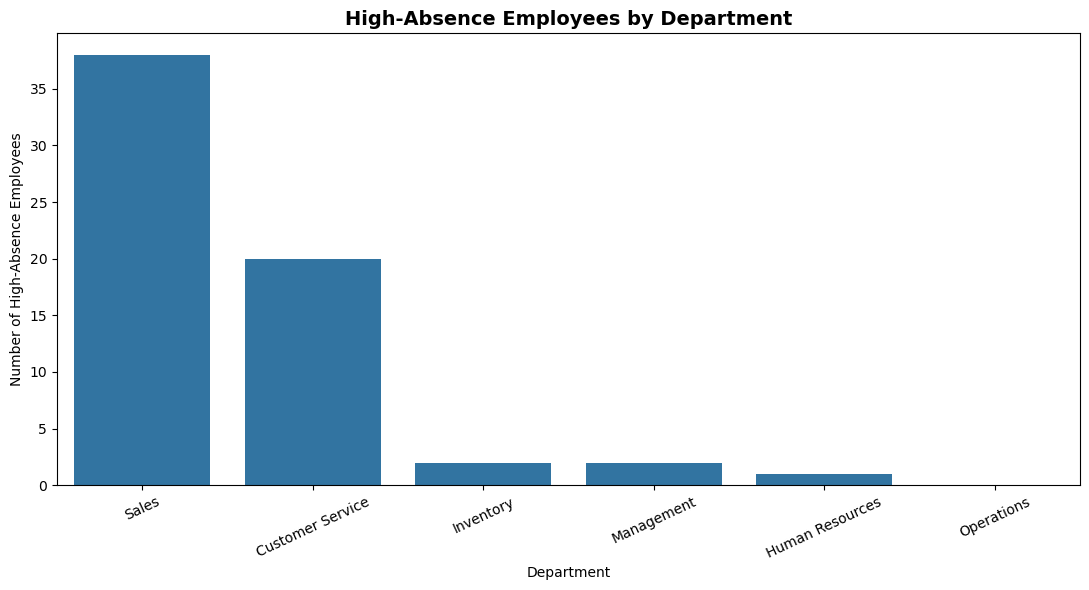

In [38]:

# Visualisation: High-Absence Employees by Department

plt.figure(figsize=(11, 6))

sns.barplot(
    data=department_outlier_summary.reset_index(),
    x='Department',
    y='High_Absence_Count'
)

plt.title(
    'High-Absence Employees by Department',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Department')
plt.ylabel('Number of High-Absence Employees')

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


In [39]:

# High-Absence Outliers by Employment Type

# 1. Count all employees by employment type
employment_total = outlier_df.groupby(
    'EmploymentType'
).agg(
    Total_Employees=('EmployeeID', 'count')
)

# 2. Count high-absence employees by employment type
employment_outliers = high_absence.groupby(
    'EmploymentType'
).agg(
    High_Absence_Count=('EmployeeID', 'count')
)

# 3. Combine results
employment_outlier_summary = employment_total.join(
    employment_outliers
).fillna(0)

# 4. Calculate percentage
employment_outlier_summary['Outlier_Percentage'] = (
    employment_outlier_summary['High_Absence_Count'] /
    employment_outlier_summary['Total_Employees'] * 100
)

# 5. Display results
print("HIGH-ABSENCE EMPLOYEES BY EMPLOYMENT TYPE")
print("-" * 65)

print(employment_outlier_summary.round(2).to_string())


HIGH-ABSENCE EMPLOYEES BY EMPLOYMENT TYPE
-----------------------------------------------------------------
                Total_Employees  High_Absence_Count  Outlier_Percentage
EmploymentType                                                         
Full-time                   862                  24                2.78
Part-time                   336                  39               11.61


In [40]:

# Top 15 Employees by Absence Rate

top_absence_employees = high_absence.sort_values(
    'AbsenceRate',
    ascending=False
).head(15)

columns_to_display = [
    'EmployeeID',
    'Department',
    'EmploymentType',
    'AgeYears',
    'LengthOfServiceYears',
    'AbsentHours',
    'AbsenceRate'
]

print("TOP 15 EMPLOYEES WITH HIGHEST ABSENCE RATES")
print("-" * 80)

print(
    top_absence_employees[columns_to_display]
    .to_string(index=False)
)


TOP 15 EMPLOYEES WITH HIGHEST ABSENCE RATES
--------------------------------------------------------------------------------
EmployeeID       Department EmploymentType  AgeYears  LengthOfServiceYears  AbsentHours  AbsenceRate
  ACE00394            Sales      Part-time        47                  2.06        600.0       0.5769
  ACE00327  Human Resources      Part-time        22                  3.55        600.0       0.4808
  ACE00826            Sales      Part-time        18                  0.00        400.0       0.3846
  ACE01001 Customer Service      Full-time        45                  5.70        720.0       0.3462
  ACE01046            Sales      Full-time        41                  0.32        496.0       0.2385
  ACE01151            Sales      Part-time        53                  1.90        248.0       0.2385
  ACE00043            Sales      Full-time        60                  0.14        496.0       0.2385
  ACE01184            Sales      Part-time        36               

In [41]:

# Validate Absence Rate Calculations

validation_df = df.dropna(
    subset=[
        'AbsentHours',
        'ScheduledHours2025',
        'AbsenceRate'
    ]
).copy()

# Calculate absence rate independently
validation_df['CalculatedAbsenceRate'] = (
    validation_df['AbsentHours'] /
    validation_df['ScheduledHours2025']
)

# Calculate differences
validation_df['RateDifference'] = (
    validation_df['AbsenceRate'] -
    validation_df['CalculatedAbsenceRate']
).abs()

# Identify discrepancies
discrepancies = validation_df[
    validation_df['RateDifference'] > 0.0001
]

print("ABSENCE RATE DATA VALIDATION")
print("-" * 60)

print("Records checked:", len(validation_df))
print("Records with discrepancies:", len(discrepancies))

print(
    "Maximum difference:",
    validation_df['RateDifference'].max()
)

print("\nTop 5 highest absence rates:")

print(
    validation_df.nlargest(5, 'AbsenceRate')[
        ['EmployeeID', 'AbsentHours',
         'ScheduledHours2025', 'AbsenceRate']
    ].to_string(index=False)
)

ABSENCE RATE DATA VALIDATION
------------------------------------------------------------
Records checked: 1198
Records with discrepancies: 0
Maximum difference: 4.8717948717948156e-05

Top 5 highest absence rates:
EmployeeID  AbsentHours  ScheduledHours2025  AbsenceRate
  ACE00394        600.0                1040       0.5769
  ACE00327        600.0                1248       0.4808
  ACE00826        400.0                1040       0.3846
  ACE01001        720.0                2080       0.3462
  ACE00043        496.0                2080       0.2385


In [42]:

# High-Absence Analysis by Department and Employment Type

# Total employees in each group
group_total = outlier_df.groupby(
    ['Department', 'EmploymentType']
).size().rename('Total_Employees')

# High-absence employees in each group
group_outliers = high_absence.groupby(
    ['Department', 'EmploymentType']
).size().rename('High_Absence_Count')

# Combine results
combined_summary = pd.concat(
    [group_total, group_outliers],
    axis=1
).fillna(0)

combined_summary['High_Absence_Count'] = (
    combined_summary['High_Absence_Count'].astype(int)
)

# Calculate outlier percentage
combined_summary['Outlier_Percentage'] = (
    combined_summary['High_Absence_Count'] /
    combined_summary['Total_Employees'] * 100
)

print("HIGH-ABSENCE ANALYSIS BY DEPARTMENT AND EMPLOYMENT TYPE")
print("-" * 75)

print(combined_summary.round(2).to_string())

HIGH-ABSENCE ANALYSIS BY DEPARTMENT AND EMPLOYMENT TYPE
---------------------------------------------------------------------------
                                 Total_Employees  High_Absence_Count  Outlier_Percentage
Department       EmploymentType                                                         
Customer Service Full-time                   135                   6                4.44
                 Part-time                    56                  14               25.00
Human Resources  Full-time                    50                   0                0.00
                 Part-time                    18                   1                5.56
Inventory        Full-time                   154                   1                0.65
                 Part-time                    74                   1                1.35
Management       Full-time                    97                   0                0.00
                 Part-time                    32                   

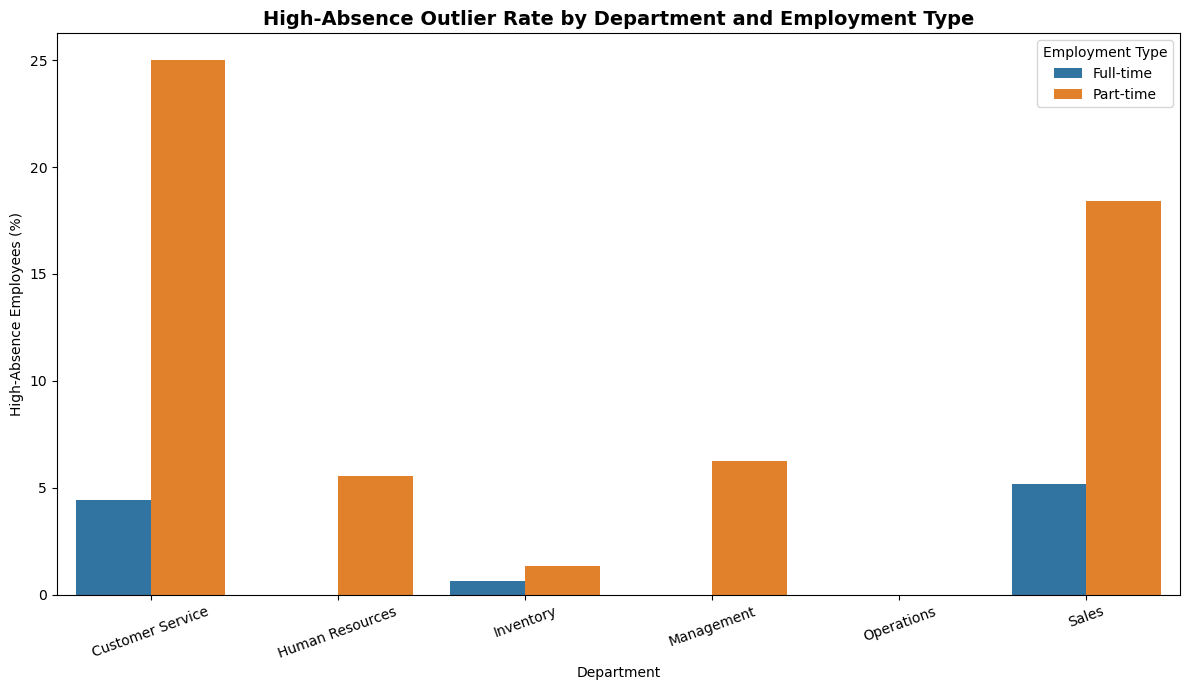

In [43]:

# Visualisation: Outlier Rate by Department and Employment Type

plot_data = combined_summary.reset_index()

plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_data,
    x='Department',
    y='Outlier_Percentage',
    hue='EmploymentType'
)

plt.title(
    'High-Absence Outlier Rate by Department and Employment Type',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Department')
plt.ylabel('High-Absence Employees (%)')

plt.legend(
    title='Employment Type',
    loc='upper right'
)

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [44]:

# Chi-Square Test: Employment Type vs High Absence Status

from scipy.stats import chi2_contingency
import numpy as np

# 1. Create a binary high-absence indicator
test_df = outlier_df.copy()

test_df['HighAbsence'] = (
    test_df['AbsenceRate'] > upper_bound
)

# 2. Create contingency table
contingency_table = pd.crosstab(
    test_df['EmploymentType'],
    test_df['HighAbsence']
)

print("CONTINGENCY TABLE")
print("-" * 50)
print(contingency_table)

# 3. Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table,
    correction=False
)

# 4. Calculate Cramer's V (effect size)
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    ))
)

# 5. Calculate outlier rates
outlier_rates = (
    contingency_table[True] /
    contingency_table.sum(axis=1) * 100
)

print("\nCHI-SQUARE TEST RESULTS")
print("-" * 50)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.10f}")
print(f"Degrees of freedom: {dof}")
print(f"Cramer's V: {cramers_v:.4f}")

print("\nOUTLIER RATES BY EMPLOYMENT TYPE")
print(outlier_rates.round(2))

# 6. Statistical conclusion
if p_value < 0.05:
    print("\nConclusion: Statistically significant association.")
else:
    print("\nConclusion: No statistically significant association.")

CONTINGENCY TABLE
--------------------------------------------------
HighAbsence     False  True 
EmploymentType              
Full-time         838     24
Part-time         297     39

CHI-SQUARE TEST RESULTS
--------------------------------------------------
Chi-square statistic: 37.7739
P-value: 0.0000000008
Degrees of freedom: 1
Cramer's V: 0.1776

OUTLIER RATES BY EMPLOYMENT TYPE
EmploymentType
Full-time     2.78
Part-time    11.61
dtype: float64

Conclusion: Statistically significant association.
